# Decoding quantum error-correcting codes: surface code vs. IBM's gross code

This notebook studies **decoding** — turning measured syndromes into corrections — for two families of quantum codes:

1. **Rotated surface code under circuit-level noise**, simulated with [Stim](https://github.com/quantumlib/Stim) and decoded with **minimum-weight perfect matching (MWPM)** via [PyMatching](https://github.com/oscarhiggott/PyMatching).
2. **The [[144, 12, 12]] bivariate bicycle "gross" code** (Bravyi et al., *Nature* 2024), a quantum LDPC code on IBM's fault-tolerance roadmap, decoded with **BP-OSD** via [ldpc](https://github.com/quantumgizmos/ldpc), and compared with surface codes at a similar and at a much larger qubit budget.
Along the way: a small study of how one decoder hyperparameter (the min-sum scaling factor) changes BP-OSD performance on the gross code.

| Part | Noise model | Codes | Decoder |
|---|---|---|---|
| 1 | circuit-level depolarizing | rotated surface code, d = 3, 5, 7 | MWPM |
| 2–4 | code capacity (i.i.d. X errors, perfect syndromes) | gross code; surface codes d = 3, 6, 12 | BP-OSD, MWPM |

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import stim, pymatching, ldpc
from ldpc import BpOsdDecoder
from qec_tools import (gross_code, planar_surface_code, code_parameters,
                       logical_z_operators, code_capacity_failures, bposd_batch)

print("stim", stim.__version__, "| pymatching", pymatching.__version__, "| ldpc", ldpc.__version__)
rng = np.random.default_rng(2026)

def binom_err(rate, shots):
    return np.sqrt(np.maximum(rate * (1 - rate), 1e-12) / shots)

stim 1.16.0 | pymatching 2.4.0 | ldpc 2.4.1


## Part 1 — Surface code threshold under circuit-level noise

Stim generates a full syndrome-extraction circuit for a distance-*d* rotated surface code memory experiment (*d* rounds), with depolarizing noise of strength *p* after every gate, on idle data qubits each round, on resets and on measurements. From the circuit Stim derives a **detector error model**; PyMatching turns it into a matching graph and decodes each shot.

Below threshold, increasing *d* should *suppress* the logical error rate; above it, larger codes do worse. The crossing point is the threshold. Because a distance-*d* experiment runs *d* rounds, we report the logical error rate **per round**, $1-(1-p_\text{shot})^{1/d}$, and also print where the per-shot curves cross.

In [2]:
def surface_memory(d, p):
    return stim.Circuit.generated(
        "surface_code:rotated_memory_z", distance=d, rounds=d,
        after_clifford_depolarization=p, before_round_data_depolarization=p,
        before_measure_flip_probability=p, after_reset_flip_probability=p)

def logical_error_per_round(d, p, target_errors=300, max_shots=300_000, chunk=20_000):
    circuit = surface_memory(d, p)
    matcher = pymatching.Matching.from_detector_error_model(
        circuit.detector_error_model(decompose_errors=True))
    sampler = circuit.compile_detector_sampler()
    shots = errors = 0
    while errors < target_errors and shots < max_shots:
        det, obs = sampler.sample(chunk, separate_observables=True)
        errors += int((matcher.decode_batch(det)[:, 0] != obs[:, 0]).sum())
        shots += chunk
    p_shot = errors / shots
    return 1 - (1 - p_shot) ** (1 / d), p_shot, errors, shots

distances = [3, 5, 7]
ps_circuit = [0.003, 0.004, 0.005, 0.006, 0.008, 0.010, 0.012, 0.014]
part1 = {}
t0 = time.time()
for d in distances:
    for p in ps_circuit:
        part1[(d, p)] = logical_error_per_round(d, p)
print(f"done in {time.time() - t0:.0f} s")
for d in distances:
    print(f"d={d}: " + "  ".join(f"{part1[(d, p)][0]:.2e}" for p in ps_circuit))

done in 5 s
d=3: 2.17e-03  3.92e-03  5.48e-03  8.03e-03  1.47e-02  2.07e-02  2.67e-02  3.63e-02
d=5: 6.93e-04  1.53e-03  2.82e-03  4.65e-03  9.58e-03  1.74e-02  2.62e-02  3.71e-02
d=7: 1.96e-04  6.21e-04  1.38e-03  2.72e-03  7.41e-03  1.56e-02  2.61e-02  3.81e-02


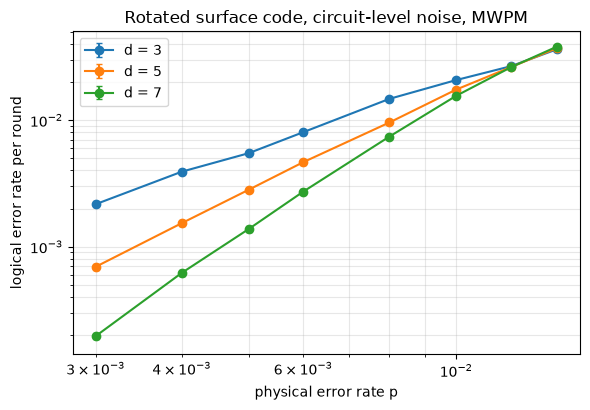

d=5 / d=7 crossing (per-round logical error rate): p ≈ 0.0122
d=5 / d=7 crossing (per-shot logical error rate): p ≈ 0.0074


In [3]:
fig, ax = plt.subplots(figsize=(6, 4.2))
for d in distances:
    pr = np.array([part1[(d, p)][0] for p in ps_circuit])
    shots = np.array([part1[(d, p)][3] for p in ps_circuit])
    ps_ = np.array([part1[(d, p)][1] for p in ps_circuit])
    err = binom_err(ps_, shots) / d          # rough per-round error bar
    ax.errorbar(ps_circuit, pr, yerr=err, marker="o", capsize=2, label=f"d = {d}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("physical error rate p"); ax.set_ylabel("logical error rate per round")
ax.set_title("Rotated surface code, circuit-level noise, MWPM")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.savefig("fig_surface_threshold.png", dpi=150); plt.show()

# Estimate where the d=5 and d=7 curves cross (log-linear interpolation),
# once for the per-round and once for the per-shot logical error rate.
def crossing(idx):
    a = np.log([part1[(5, p)][idx] for p in ps_circuit])
    b = np.log([part1[(7, p)][idx] for p in ps_circuit])
    diff = b - a
    i = np.where(np.sign(diff[:-1]) != np.sign(diff[1:]))[0]
    if not i.size:
        return None
    i = i[0]
    x0, x1 = ps_circuit[i], ps_circuit[i + 1]
    return x0 + (x1 - x0) * (-diff[i]) / (diff[i + 1] - diff[i])

for name, idx in [("per-round", 0), ("per-shot", 1)]:
    pc = crossing(idx)
    print(f"d=5 / d=7 crossing ({name} logical error rate): " + (f"p ≈ {pc:.4f}" if pc else "not in range"))

## Part 2 — Building the gross code

A bivariate bicycle code is defined by two matrices built from commuting cyclic shifts
$x = S_\ell \otimes I_m$ and $y = I_\ell \otimes S_m$. For the gross code, $\ell = 12$, $m = 6$ and

$$A = x^3 + y + y^2, \qquad B = y^3 + x + x^2, \qquad H_X = [A \mid B], \qquad H_Z = [B^\top \mid A^\top].$$

Because $A$ and $B$ commute, $H_X H_Z^\top = AB + BA = 0 \pmod 2$, so the checks commute. Every check has weight 6 and every qubit is in 3 X-checks and 3 Z-checks — this is what makes the code **LDPC**.

We verify $n$ and $k = n - \mathrm{rank}(H_X) - \mathrm{rank}(H_Z)$ and compute a basis of logical Z operators (kernel of $H_X$ modulo the row space of $H_Z$). Computing the distance exactly is expensive; we only check that our logical basis is consistent with $d = 12$ reported in the paper.

In [4]:
H_X, H_Z = gross_code()
n, k = code_parameters(H_X, H_Z)
L_Z = logical_z_operators(H_X, H_Z)
print(f"gross code: n = {n}, k = {k}")
print("check weights:", sorted(set(H_X.sum(1))), "| qubit degree in H_Z:", sorted(set(H_Z.sum(0))))
print("logical Z basis:", L_Z.shape, "| weights of basis vectors:", sorted(L_Z.sum(1)))

surface = {}
for d in [3, 6, 12]:
    hx, hz = planar_surface_code(d)
    surface[d] = (hz, logical_z_operators(hx, hz))
    print(f"surface code d={d}: [[n, k]] = {code_parameters(hx, hz)}")

gross code: n = 144, k = 12
check weights: [np.uint64(6)] | qubit degree in H_Z: [np.uint64(3)]
logical Z basis: (12, 144) | weights of basis vectors: [np.uint64(12), np.uint64(12), np.uint64(12), np.uint64(12), np.uint64(12), np.uint64(12), np.uint64(12), np.uint64(24), np.uint64(28), np.uint64(34), np.uint64(36), np.uint64(38)]
surface code d=3: [[n, k]] = (13, 1)
surface code d=6: [[n, k]] = (61, 1)
surface code d=12: [[n, k]] = (265, 1)


## Part 3 — How sensitive is BP-OSD to the min-sum scaling factor?

BP-OSD runs **belief propagation** on the Tanner graph; if BP does not converge to a solution consistent with the syndrome, **ordered-statistics decoding** (OSD) post-processes the BP soft information. With the *min-sum* approximation of BP, messages are usually multiplied by a scaling factor α < 1 because plain min-sum overestimates their reliability.

Quantum LDPC codes are highly **degenerate** and their Tanner graphs contain many short cycles, which makes BP alone struggle. Here we measure the gross code's failure rate at p = 4 % for several α, with the OSD stage fixed (combination sweep, order 7).

In [5]:
p_test = 0.04
part3 = {}
for alpha in [1.0, 0.9, 0.75, 0.625, 0.5]:
    dec = BpOsdDecoder(H_Z, error_rate=p_test, max_iter=100, bp_method="minimum_sum",
                       ms_scaling_factor=alpha, osd_method="osd_cs", osd_order=7)
    rate, f, s = code_capacity_failures(H_Z, L_Z, p_test, bposd_batch(dec), rng,
                                        target_failures=10**9, max_shots=10_000)
    part3[alpha] = (rate, f, s)
    print(f"alpha = {alpha:<5}  failure rate = {rate:.4f}  ({f}/{s})")

alpha = 1.0    failure rate = 0.2271  (2271/10000)
alpha = 0.9    failure rate = 0.0118  (118/10000)
alpha = 0.75   failure rate = 0.0108  (108/10000)
alpha = 0.625  failure rate = 0.0111  (111/10000)
alpha = 0.5    failure rate = 0.0091  (91/10000)


## Part 4 — Gross code vs. surface codes (code capacity)

The gross code stores **12 logical qubits in 144 data qubits**. We compare the probability that *any* of 12 logical qubits fails against storing 12 logical qubits in 12 independent surface-code patches:

| Encoding of 12 logical qubits | data qubits |
|---|---|
| gross code [[144, 12, 12]] | 144 |
| 12 × surface code d = 3 ([[13, 1, 3]]) | 156 |
| 12 × surface code d = 6 ([[61, 1, 6]]) | 732 |
| 12 × surface code d = 12 ([[265, 1, 12]]) | 3 180 |

For independent patches, $P_{\text{fail}}^{(12)} = 1 - (1 - p_L)^{12}$, where $p_L$ is the single-patch failure rate. Surface codes are decoded with MWPM; the gross code with BP-OSD (α = 0.625, OSD-CS order 7). As a decoder cross-check, the d = 6 surface code is also decoded with BP-OSD.

In [6]:
ps_cc = [0.01, 0.015, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08]
part4 = {"gross": {}, "sc6_bposd": {}, **{f"sc{d}": {} for d in surface}}
t0 = time.time()
for p in ps_cc:
    dec = BpOsdDecoder(H_Z, error_rate=p, max_iter=100, bp_method="minimum_sum",
                       ms_scaling_factor=0.625, osd_method="osd_cs", osd_order=7)
    part4["gross"][p] = code_capacity_failures(H_Z, L_Z, p, bposd_batch(dec), rng,
                                               target_failures=200, max_shots=200_000)
    for d, (hz, lz) in surface.items():
        m = pymatching.Matching(hz, weights=np.log((1 - p) / p))
        part4[f"sc{d}"][p] = code_capacity_failures(hz, lz, p, m.decode_batch, rng,
                                                    target_failures=200, max_shots=1_000_000,
                                                    chunk=50_000)
    hz6, lz6 = surface[6]
    dec6 = BpOsdDecoder(hz6, error_rate=p, max_iter=100, bp_method="minimum_sum",
                        ms_scaling_factor=0.625, osd_method="osd_cs", osd_order=7)
    part4["sc6_bposd"][p] = code_capacity_failures(hz6, lz6, p, bposd_batch(dec6), rng,
                                                   target_failures=200, max_shots=100_000)
print(f"done in {time.time() - t0:.0f} s")

def twelve(rate):
    return 1 - (1 - rate) ** 12

print(f"{'p':>6} | {'gross':>9} | {'12xSC3':>9} | {'12xSC6':>9} | {'12xSC12':>9} | {'12xSC6 BP-OSD':>13}")
for p in ps_cc:
    g = part4["gross"][p]
    row = [g[0]] + [twelve(part4[f"sc{d}"][p][0]) for d in surface] + [twelve(part4["sc6_bposd"][p][0])]
    note = f"   (gross: {g[1]} failures in {g[2]} shots)"
    print(f"{p:>6} | " + " | ".join(f"{v:>9.2e}" for v in row[:4]) + f" | {row[4]:>13.2e}" + note)

done in 150 s
     p |     gross |    12xSC3 |    12xSC6 |   12xSC12 | 12xSC6 BP-OSD
  0.01 |  9.00e-05 |  2.98e-02 |  9.00e-04 |  0.00e+00 |      8.40e-04   (gross: 18 failures in 200000 shots)
 0.015 |  3.80e-04 |  6.00e-02 |  4.05e-03 |  1.20e-05 |      4.43e-03   (gross: 76 failures in 200000 shots)
  0.02 |  8.40e-04 |  9.82e-02 |  9.24e-03 |  4.80e-05 |      1.05e-02   (gross: 168 failures in 200000 shots)
  0.03 |  2.89e-03 |  1.99e-01 |  4.56e-02 |  1.02e-03 |      4.33e-02   (gross: 202 failures in 70000 shots)
  0.04 |  1.13e-02 |  3.25e-01 |  1.01e-01 |  7.28e-03 |      1.04e-01   (gross: 226 failures in 20000 shots)
  0.05 |  3.42e-02 |  4.54e-01 |  2.02e-01 |  3.19e-02 |      2.09e-01   (gross: 342 failures in 10000 shots)
  0.06 |  8.20e-02 |  5.59e-01 |  3.48e-01 |  1.06e-01 |      3.35e-01   (gross: 410 failures in 5000 shots)
  0.07 |  1.63e-01 |  6.65e-01 |  4.88e-01 |  2.46e-01 |      4.70e-01   (gross: 817 failures in 5000 shots)
  0.08 |  2.86e-01 |  7.41e-01 |  6.

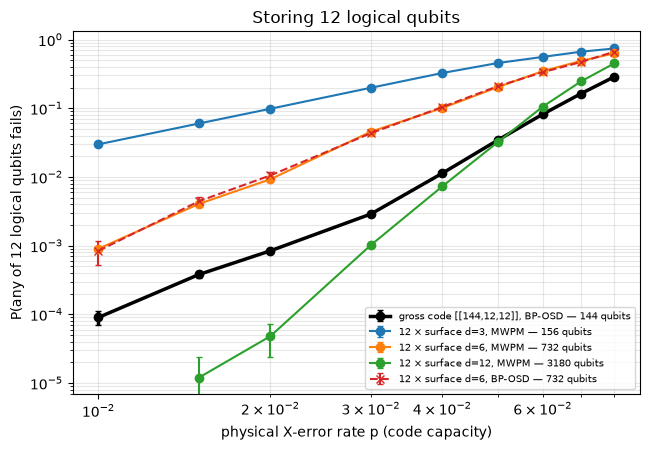

In [7]:
fig, ax = plt.subplots(figsize=(6.6, 4.6))
def plot_series(key, label, transform, **kw):
    xs, ys, es = [], [], []
    for p in ps_cc:
        rate, f, s = part4[key][p]
        if f == 0:
            continue
        xs.append(p); ys.append(transform(rate)); es.append(12 * binom_err(rate, s) if transform is twelve else binom_err(rate, s))
    ax.errorbar(xs, ys, yerr=es, marker=kw.pop("marker", "o"), capsize=2, label=label, **kw)

plot_series("gross", "gross code [[144,12,12]], BP-OSD — 144 qubits", lambda r: r, lw=2.5, color="k")
plot_series("sc3", "12 × surface d=3, MWPM — 156 qubits", twelve)
plot_series("sc6", "12 × surface d=6, MWPM — 732 qubits", twelve)
plot_series("sc12", "12 × surface d=12, MWPM — 3180 qubits", twelve)
plot_series("sc6_bposd", "12 × surface d=6, BP-OSD — 732 qubits", twelve, ls="--", marker="x")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("physical X-error rate p (code capacity)")
ax.set_ylabel("P(any of 12 logical qubits fails)")
ax.set_title("Storing 12 logical qubits")
ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); plt.savefig("fig_gross_vs_surface.png", dpi=150); plt.show()

## Part 5 — Takeaways and limitations

**What the numbers show** (exact values are in the printed tables above):

* *Surface code, circuit level.* Below threshold, increasing the distance suppresses the logical error rate: at p = 0.3 %, going from d = 3 to d = 7 lowers the per-round logical error rate by about 10×. The d = 5 / d = 7 curves cross at p ≈ 0.8 % (per shot) or ≈ 1.3 % (per round) in this run. The estimate is only approximate: near the crossing, the curves differ by less than their statistical noise, and the value depends on the normalisation.
* *Decoder hyperparameters matter.* On the gross code at p = 4 %, plain min-sum BP (α = 1) followed by OSD fails about 20× more often than normalised min-sum (α ≤ 0.9). A single decoder parameter changes the conclusion about the code.
* *Low overhead.* At p = 1–2 %, the gross code (144 qubits) fails roughly 100–330× less often than 12 surface-code patches with a similar qubit budget (12 × d = 3, 156 qubits), and about 10× less often than 12 × d = 6 patches that use 5× more qubits (732).
* *But not a free lunch.* 12 × d = 12 surface-code patches (3 180 qubits, 22× more) are still clearly better at low p (no failures in 10⁶ shots at p = 1 %); the gross code only catches up around p ≈ 5 % and is better above that. Equal distance does not mean equal protection. Plausible reasons are the many low-weight logical operators shared by 12 logical qubits and the sub-optimality of BP-OSD compared with MWPM on the surface code. This notebook does not separate the two effects.
* *MWPM vs BP-OSD on the surface code.* Both decoders give nearly identical results on the d = 6 surface code. MWPM is the natural choice for surface codes because every single error flips at most two checks (a graph). qLDPC codes lack this structure, which is why BP-based decoders are used for them.

**Limitations of this study**

* Parts 2–4 use *code capacity* noise (perfect syndrome measurements, X errors only). Real devices have measurement errors and circuit-level noise, which lower all thresholds. The gross code's circuit-level performance in Bravyi et al. requires a specific syndrome-extraction circuit and long-range couplings.
* BP-OSD with order-7 OSD is accurate but slow; real-time decoding at hardware speed is an open engineering problem (IBM's recent work on BP-based real-time decoders such as Relay-BP addresses this).
* Monte Carlo points with few failures have large relative uncertainty; error bars are binomial standard errors.

**References**

* S. Bravyi, A. W. Cross, J. M. Gambetta, D. Maslov, P. Rall, T. J. Yoder, *High-threshold and low-overhead fault-tolerant quantum memory*, Nature 627, 778 (2024).
* C. Gidney, *Stim: a fast stabilizer circuit simulator*, Quantum 5, 497 (2021).
* O. Higgott, C. Gidney, *Sparse Blossom: correcting a million errors per core second with minimum-weight matching*, Quantum 9, 1600 (2025).
* P. Panteleev, G. Kalachev, *Degenerate quantum LDPC codes with good finite length performance*, Quantum 5, 585 (2021).
* J. Roffe, D. R. White, S. Burton, E. Campbell, *Decoding across the quantum low-density parity-check code landscape*, Phys. Rev. Research 2, 043423 (2020).
* T. Müller et al., *Improved belief propagation is sufficient for real-time decoding of quantum memory*, arXiv:2506.01779 (2025).